# Steam Game Success Prediction

Can we predict whether players will like a Steam game **before anyone reviews it**?

This notebook trains classifiers to predict whether a game will be well received using only information available at launch: its genres, tags, feature specs, title, and release year. Player reviews are used to *define* the success label, but review-derived features are deliberately kept out of the model's inputs. Including them would leak the label into the features and make the task unrealistic, since a studio or storefront would want this signal before reviews exist.

**Data**

- `steam_games.json`: one row per Steam title with metadata such as title, genres, tags, specs, price, and release date
- `australian_user_reviews.json`: per-user reviews, flattened into one row per review with a recommend / not-recommend flag

**Workflow**

1. Data loading and cleaning
2. Exploratory data analysis
3. Feature engineering (launch-time features only)
4. Defining the success label
5. Train / validation / test split
6. Baselines (majority class, logistic regression)
7. Tuned tree ensembles (random forest, gradient boosting)
8. Final model on the held-out test set
9. Data source and related work
10. Error analysis

*Built for DSC 256 in the UC San Diego M.S. in Data Science program.*

In [1]:
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    classification_report,
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import ast


## 1. Data loading

We first load the two JSON‑lines files provided for the project:

- `steam_games.json`: metadata for each game (an `id`, title, price, genres, categories, and release date).  
- `australian_user_reviews.json`: nested per–user dictionaries, where each line contains a `user_id` and a list of
  that user’s reviews.

Because the files are stored as one JSON object per line, we stream them line‑by‑line, parse each line with
`ast.literal_eval`, and collect the results into Python lists before converting them to Pandas DataFrames.

A few small but important cleaning steps:

- For the games table we rename the column `id` to `item_id` (if needed) and cast it to string.  
- For the reviews table we flatten the nested structure so that each row corresponds to a single review, and we attach
  the `user_id` to each review.  
- We then standardize the game identifier in the reviews table by renaming any of `appid`, `app_id`, or `id` to
  `item_id` and casting it to string so that it can be joined to the games table later.

At the end of this step we have two clean DataFrames, `games_df` and `reviews_df`, keyed on a common `item_id`
identifier.


In [2]:
# Adjust the paths here if your data lives somewhere else
GAMES_PATH = "steam_games.json"
REVIEWS_PATH = "australian_user_reviews.json"

# ---- Load steam_games.json ----
games = []
with open(GAMES_PATH, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        try:
            games.append(ast.literal_eval(line))
        except Exception as e:
            # If there are any malformed lines, just skip them
            print(f"Skipping bad line in games file: {e}")

games_df = pd.DataFrame(games)

# Make sure we have an item_id column as string
if "id" in games_df.columns and "item_id" not in games_df.columns:
    games_df = games_df.rename(columns={"id": "item_id"})
games_df["item_id"] = games_df["item_id"].astype(str)

print("Games shape:", games_df.shape)
games_df.head()

print(games_df.columns)


Games shape: (32135, 16)
Index(['publisher', 'genres', 'app_name', 'title', 'url', 'release_date',
       'tags', 'discount_price', 'reviews_url', 'specs', 'price',
       'early_access', 'item_id', 'developer', 'sentiment', 'metascore'],
      dtype='object')


In [3]:
# ---- Load australian_user_reviews.json ----
reviews = []
with open(REVIEWS_PATH, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        try:
            user_data = ast.literal_eval(line)
            user_id = user_data.get("user_id")
            for review in user_data.get("reviews", []):
                # Each review is a dict; copy it so we can safely mutate
                review_entry = dict(review)
                review_entry["user_id"] = user_id
                reviews.append(review_entry)
        except Exception as e:
            print(f"Skipping bad line in reviews file: {e}")

reviews_df = pd.DataFrame(reviews)

# Standardize the item id column
if "item_id" not in reviews_df.columns:
    # Some datasets call this appid, game_id, etc.; adjust if needed.
    for candidate in ["appid", "app_id", "id"]:
        if candidate in reviews_df.columns:
            reviews_df = reviews_df.rename(columns={candidate: "item_id"})
            break

reviews_df["item_id"] = reviews_df["item_id"].astype(str)

print("Reviews shape:", reviews_df.shape)
reviews_df.head()

print(reviews_df.columns)


Reviews shape: (59305, 8)
Index(['funny', 'posted', 'last_edited', 'item_id', 'helpful', 'recommend',
       'review', 'user_id'],
      dtype='object')


## 2. Quick EDA

Before committing to any modeling choices, we do a light sanity check on the games and reviews:

- Count how many unique games appear in `games_df` versus `reviews_df`.  
- Inspect the set of columns in each DataFrame to confirm that the expected fields are present.  
- Compute how many reviews each game has and plot the distribution of review counts.

The review histogram confirms a highly skewed distribution: a small number of popular titles accumulate thousands of
reviews, while the long tail of games has only a handful of reviews. This motivates using both the **number of reviews**
and the **share of positive reviews** when defining a success label, and suggests that we should be cautious about
learning from games with only one or two reviews.


Unique games in games_df: 32133
Unique games in reviews_df: 3682

Reviews per game (head):
item_id
730       3759
440       3736
4000      1735
570       1562
218620    1137
Name: count, dtype: int64


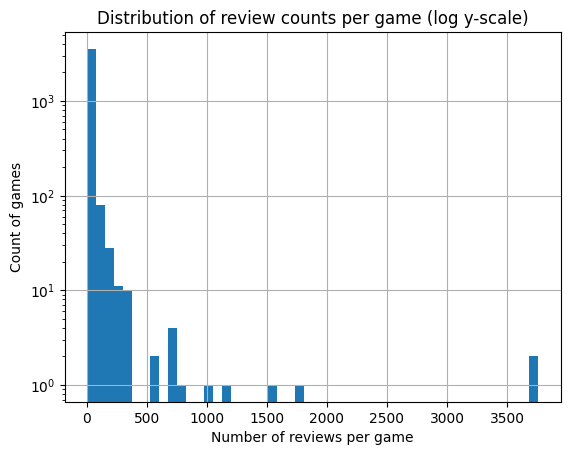

In [4]:
# Number of unique games in each table
print("Unique games in games_df:", games_df["item_id"].nunique())
print("Unique games in reviews_df:", reviews_df["item_id"].nunique())

# Reviews per game
reviews_per_game = reviews_df["item_id"].value_counts()
print("\nReviews per game (head):")
print(reviews_per_game.head())

plt.figure()
reviews_per_game.hist(bins=50)
plt.xlabel("Number of reviews per game")
plt.ylabel("Count of games")
plt.yscale("log")
plt.title("Distribution of review counts per game (log y-scale)")
plt.show()


## 3. Feature engineering

### 3.0 Review aggregates (used for the label only)

The raw review data has one row per review, so we first aggregate to one row per game:

- `n_reviews`: number of reviews the game received
- `pos_share`: fraction of those reviews that recommend the game
- `log_n_reviews`: log-transformed review count

These aggregates are used to **build the success label** in the next cell. They are dropped from the model inputs in section 3.2, because a model that sees the share of positive reviews is effectively being handed the answer.

In [ ]:
POS_THRESHOLD = 0.75
MIN_REVIEWS_FOR_LABEL = 2


game_review_features = (
    reviews_df.groupby("item_id")
    .agg(
        n_reviews=("recommend", "size"),
        n_pos=("recommend", lambda s: (s == True).sum()),
    )
    .reset_index()
)

# Positive share: fraction of reviews that recommend the game
game_review_features["pos_share"] = (
    game_review_features["n_pos"] / game_review_features["n_reviews"]
)


# Binary success label from pos_share
game_review_features["success"] = (
    (game_review_features["n_reviews"] >= MIN_REVIEWS_FOR_LABEL)
    & (game_review_features["pos_share"] >= POS_THRESHOLD)
).astype(int)


# Log-transformed review count
game_review_features["log_n_reviews"] = np.log1p(game_review_features["n_reviews"])

# Keep what we need going forward
game_review_features = game_review_features[
    ["item_id", "n_reviews", "log_n_reviews", "pos_share", "success"]
]


print(game_review_features.head())
print("Game review feature shape:", game_review_features.shape)
print(game_review_features.describe())


Reviews shape: (59305, 8)
Review columns: ['funny', 'posted', 'last_edited', 'item_id', 'helpful', 'recommend', 'review', 'user_id']
  item_id  n_reviews  log_n_reviews  pos_share  success
0      10         57       4.060443   0.982456        1
1   10090         52       3.970292   0.980769        1
2   10130          2       1.098612   1.000000        1
3   10140          1       0.693147   1.000000        0
4   10150          9       2.302585   1.000000        1
Game review feature shape: (3682, 5)
         n_reviews  log_n_reviews    pos_share      success
count  3682.000000    3682.000000  3682.000000  3682.000000
mean     16.106735       1.567735     0.803689     0.433732
std     107.769088       1.140280     0.323680     0.495656
min       1.000000       0.693147     0.000000     0.000000
25%       1.000000       0.693147     0.727273     0.000000
50%       2.000000       1.098612     1.000000     0.000000
75%       6.000000       1.945910     1.000000     1.000000
max    3759.00

### 3.1 Launch-time game features

These are the features the model actually uses, all available before a game has any reviews:

- **Release year**, parsed from inconsistent date strings
- **Number of genres** and **number of tags** (falling back to specs when tags are missing)
- **`text_features`**: genres, tags, specs, and title combined into one string, later vectorized with TF-IDF

Price is parsed here but not used in the final model.

In [6]:
games_features = games_df.copy()

# Ensure item_id is string for consistent merging
games_features["item_id"] = games_features["item_id"].astype(str)

# ----- Price (if present) -----
for col in ["price", "price_final", "initialprice"]:
    if col in games_features.columns:
        games_features[col] = pd.to_numeric(games_features[col], errors="coerce")
        games_features = games_features.rename(columns={col: "price"})
        break

if "price" not in games_features.columns:
    games_features["price"] = np.nan

# ----- Release year -----
year_col = None
for c in games_features.columns:
    if "release" in c.lower() and "date" in c.lower():
        year_col = c
        break

import re

def extract_year(x):
    if pd.isna(x):
        return np.nan
    digits = re.findall(r"(19\d{2}|20\d{2})", str(x))
    if digits:
        return int(digits[-1])
    return np.nan

if year_col is not None:
    games_features["release_year"] = games_features[year_col].apply(extract_year)
else:
    games_features["release_year"] = np.nan

# ----- Number of genres -----
if "genres" in games_features.columns:
    games_features["n_genres"] = games_features["genres"].astype(str).apply(
        lambda s: len([x for x in s.split(",") if x.strip()])
    )
else:
    games_features["n_genres"] = 0

# ----- Number of "categories" (we approximate with tags/specs if present) -----
if "tags" in games_features.columns:
    games_features["n_categories"] = games_features["tags"].astype(str).apply(
        lambda s: len([x for x in s.split(",") if x.strip()])
    )
elif "specs" in games_features.columns:
    games_features["n_categories"] = games_features["specs"].astype(str).apply(
        lambda s: len([x for x in s.split(",") if x.strip()])
    )
else:
    games_features["n_categories"] = 0

# ----- Text features for TF-IDF -----

# Identify possible text-like columns
text_cols = []
for col in ["genres", "tags", "specs", "title", "app_name"]:
    if col in games_features.columns:
        text_cols.append(col)

def clean_text_value(val):
    """Convert lists, arrays, floats, NaNs, or weird types into a clean string."""
    if isinstance(val, list) or isinstance(val, tuple):
        return " ".join(str(x) for x in val)
    if isinstance(val, dict):
        return " ".join(str(x) for x in val.values())
    # arrays from numpy
    if hasattr(val, "shape"):
        return " ".join(str(x) for x in val.tolist())
    if pd.isna(val):
        return ""
    return str(val)

def build_text(row):
    parts = []
    for c in text_cols:
        val = clean_text_value(row[c])
        parts.append(val)
    return " ".join(parts)

games_features["text_features"] = games_features.apply(build_text, axis=1)

# Keep only the columns we actually use
keep_cols = ["item_id", "price", "release_year", "n_genres", "n_categories", "text_features"]
games_features = games_features[keep_cols]

games_features.head()


,item_id,price,release_year,n_genres,n_categories,text_features
0,761140,4.99,2018.0,5,5,Action Casual Indie Simulation Strategy Strate...
1,643980,NaN,2018.0,4,19,Free to Play Indie RPG Strategy Free to Play S...
2,670290,NaN,2017.0,5,6,Casual Free to Play Indie Simulation Sports Fr...
3,767400,0.99,2017.0,3,3,Action Adventure Casual Action Adventure Casua...
4,773570,2.99,NaN,1,4,Action Indie Casual Sports Single-player Full...


### 3.2 Merge and remove review-derived columns

We inner-join the review aggregates and the metadata on `item_id`, keeping only games that appear in both tables. We then drop every review-derived column (`n_reviews`, `log_n_reviews`, `pos_share`) from the modeling table, leaving only launch-time features and the `success` label.

In [7]:
data = game_review_features.merge(games_features, on="item_id", how="inner")

# Drop 'price' if you’re not using it
if "price" in data.columns:
    data = data.drop(columns=["price"])

# Make sure text_features has no NaNs
data["text_features"] = data["text_features"].fillna("")

# --- Build modeling dataset WITHOUT review-based features ---

# Columns we do NOT want the model to use as inputs
review_cols = ["n_reviews", "log_n_reviews", "pos_share", "n_pos"]

# Make a copy just for modeling so original `data` is preserved
model_data = data.copy()

# Drop review-derived feature columns from the model data
model_data = model_data.drop(columns=[c for c in review_cols if c in model_data.columns])

# We will keep only:
# - release_year (numeric)
# - n_genres, n_categories (numeric)
# - text_features (TF-IDF input)
# - success (label)
print("Model data columns:", model_data.columns.tolist())
model_data.head()



Model data columns: ['item_id', 'success', 'release_year', 'n_genres', 'n_categories', 'text_features']


,item_id,success,release_year,n_genres,n_categories,text_features
0,10,1,2000.0,1,20,Action Action FPS Multiplayer Shooter Classic ...
1,10090,1,2008.0,1,20,Action Zombies World War II FPS Action Multipl...
2,10130,1,2007.0,1,13,Action Action FPS Time Manipulation Sci-fi Fir...
3,10140,0,2006.0,1,4,Sports Sports Mini Golf Golf Local Multiplayer...
4,10150,1,2009.0,2,20,Action Adventure Action Open World Adventure T...


## 4. Define the target: what is a "successful" game?

The dataset has no success label, so we construct one from review history (computed in section 3.0). A game is labeled **successful** (`success = 1`) if:

- it has at least `MIN_REVIEWS_FOR_LABEL = 2` reviews, and
- at least `POS_THRESHOLD = 75%` of its reviews recommend it.

This treats success as **player satisfaction** rather than sales. The thresholds are a judgment call: half the games have only one or two reviews, so a higher minimum would give cleaner labels at the cost of a much smaller dataset.

## 5. Train / validation / test split

We use a stratified **80 / 10 / 10** split:

1. Hold out 20% of games, stratified by label.
2. Split that 20% in half into a **validation set** (for comparing models and tuning) and a **test set** (touched once, at the very end).

Stratifying keeps the share of successful games consistent across all three sets.

In [8]:
# Features we want the model to see
numeric_features = ["release_year", "n_genres", "n_categories"]
text_feature = "text_features"

# Sanity check: make sure the columns exist
print("Numeric features present:", [c for c in numeric_features if c in model_data.columns])
print("Has text_features?", text_feature in model_data.columns)

# Build X and y
X = model_data[numeric_features + [text_feature]]
y = model_data["success"]

print("data shape:", model_data.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("success value counts:\n", y.value_counts(dropna=False))

# Train/val/test split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print("Train size:", X_train.shape[0])
print("Val size:", X_val.shape[0])
print("Test size:", X_test.shape[0])


Numeric features present: ['release_year', 'n_genres', 'n_categories']
Has text_features? True
data shape: (3195, 6)
X shape: (3195, 4)
y shape: (3195,)
success value counts:
 success
0    1770
1    1425
Name: count, dtype: int64
Train size: 2556
Val size: 319
Test size: 320


## 6. Baseline models

Two baselines set the bar for the tuned models:

1. **Majority class:** always predict the most common label. Any useful model has to beat this.
2. **Logistic regression** on scaled numeric features plus TF-IDF text features, with balanced class weights. This is a strong baseline for sparse, high-dimensional text features.


Dummy (most frequent)
Accuracy:  0.555
Precision: 0.000
Recall:    0.000
F1:        0.000
ROC AUC:   0.500


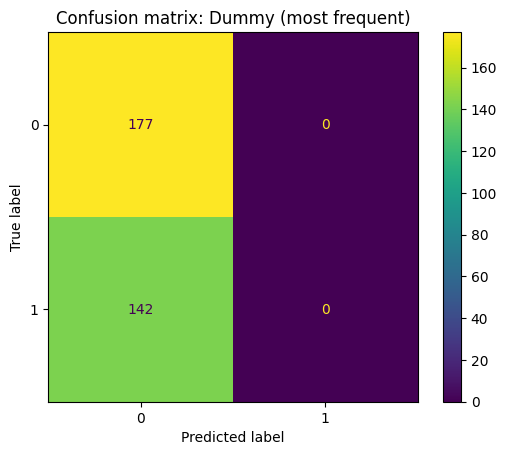


Classification report:
              precision    recall  f1-score   support

           0       0.55      1.00      0.71       177
           1       0.00      0.00      0.00       142

    accuracy                           0.55       319
   macro avg       0.28      0.50      0.36       319
weighted avg       0.31      0.55      0.40       319



In [9]:
def evaluate_model(name, model, X_tr, y_tr, X_v, y_v):
    print(f"\n{name}")
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_v)
    y_proba = None
    try:
        y_proba = model.predict_proba(X_v)[:, 1]
    except Exception:
        pass

    acc = accuracy_score(y_v, y_pred)
    prec = precision_score(y_v, y_pred, zero_division=0)
    rec = recall_score(y_v, y_pred, zero_division=0)
    f1 = f1_score(y_v, y_pred, zero_division=0)
    print(f"Accuracy:  {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall:    {rec:.3f}")
    print(f"F1:        {f1:.3f}")

    if y_proba is not None:
        try:
            auc = roc_auc_score(y_v, y_proba)
            print(f"ROC AUC:   {auc:.3f}")
        except Exception as e:
            print("Could not compute ROC AUC:", e)

    disp = ConfusionMatrixDisplay.from_predictions(y_v, y_pred)
    disp.ax_.set_title(f"Confusion matrix: {name}")
    plt.show()

    print("\nClassification report:")
    print(classification_report(y_v, y_pred, zero_division=0))


from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
evaluate_model("Dummy (most frequent)", dummy, X_train[numeric_features], y_train, X_val[numeric_features], y_val)




Logistic Regression (TF-IDF + metadata)
Accuracy:  0.743
Precision: 0.695
Recall:    0.754
F1:        0.723
ROC AUC:   0.817


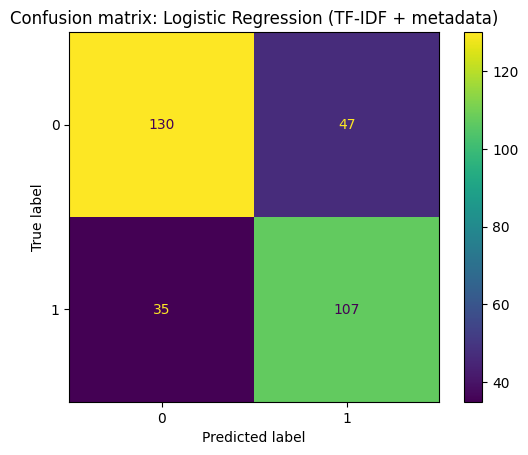


Classification report:
              precision    recall  f1-score   support

           0       0.79      0.73      0.76       177
           1       0.69      0.75      0.72       142

    accuracy                           0.74       319
   macro avg       0.74      0.74      0.74       319
weighted avg       0.75      0.74      0.74       319



In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer

# Numeric pipeline: impute missing years, then scale
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Text pipeline: TF-IDF on genres/categories/tags/etc in text_features
text_transformer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
)

# ColumnTransformer: numeric + text -> single feature matrix
preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("txt", text_transformer, text_feature),
    ],
    remainder="drop",
    sparse_threshold=0.0  # force dense output (helps GradientBoosting)
)

log_reg = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]
)

evaluate_model("Logistic Regression (TF-IDF + metadata)", log_reg, X_train, y_train, X_val, y_val)


## 7. Tree ensembles

Next we try **random forest** and **gradient boosting**, which can capture non-linear interactions between features. Each is tuned with a small 3-fold `GridSearchCV` over the training set, optimizing F1, then evaluated on the validation set.

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best RF params: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
RF train accuracy: 0.6249790898359215

Random Forest (best, TF-IDF + metadata, no reviews)
Accuracy:  0.734
Precision: 0.728
Recall:    0.641
F1:        0.682
ROC AUC:   0.791


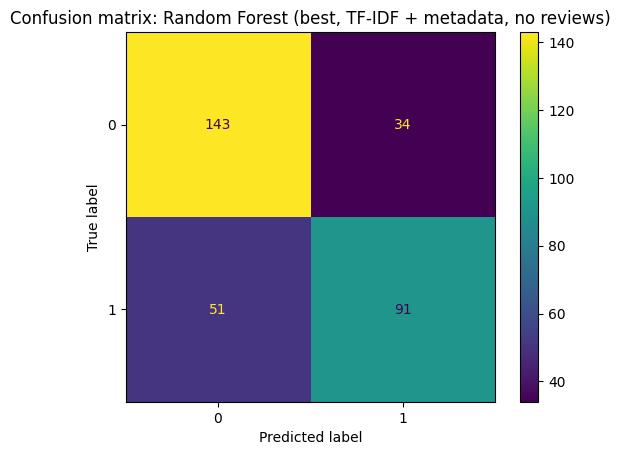


Classification report:
              precision    recall  f1-score   support

           0       0.74      0.81      0.77       177
           1       0.73      0.64      0.68       142

    accuracy                           0.73       319
   macro avg       0.73      0.72      0.73       319
weighted avg       0.73      0.73      0.73       319



In [11]:

rf_pipeline = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("clf", RandomForestClassifier(random_state=42, n_jobs=-1)),
    ]
)

rf_param_grid = {
    "clf__n_estimators": [200, 400],
    "clf__max_depth": [None, 10],
    "clf__min_samples_split": [2, 5],
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

rf_grid.fit(X_train, y_train)
print("Best RF params:", rf_grid.best_params_)
print("RF train accuracy:", rf_grid.best_score_)  # CV score, not real train acc

best_rf = rf_grid.best_estimator_

evaluate_model("Random Forest (best, TF-IDF + metadata, no reviews)",
               best_rf, X_train, y_train, X_val, y_val)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best GB params: {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__n_estimators': 100}

Gradient Boosting (best CV, TF-IDF + metadata, no reviews)
Accuracy:  0.715
Precision: 0.689
Recall:    0.655
F1:        0.671
ROC AUC:   0.805


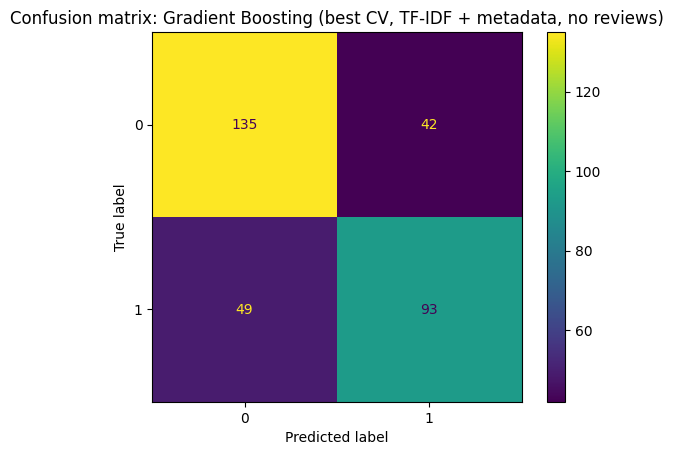


Classification report:
              precision    recall  f1-score   support

           0       0.73      0.76      0.75       177
           1       0.69      0.65      0.67       142

    accuracy                           0.71       319
   macro avg       0.71      0.71      0.71       319
weighted avg       0.71      0.71      0.71       319



In [12]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("clf", GradientBoostingClassifier(random_state=42)),
    ]
)

gb_param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__learning_rate": [0.05, 0.1],
    "clf__max_depth": [2, 3],
}

gb_grid = GridSearchCV(
    gb_pipeline,
    gb_param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

gb_grid.fit(X_train, y_train)
print("Best GB params:", gb_grid.best_params_)

best_gb = gb_grid.best_estimator_

evaluate_model("Gradient Boosting (best CV, TF-IDF + metadata, no reviews)",
               best_gb, X_train, y_train, X_val, y_val)


## 8. Final model and test performance

**Validation results**

| Model | Accuracy | Precision | Recall | F1 | ROC AUC |
|---|---|---|---|---|---|
| Majority class | 0.555 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic regression | **0.743** | 0.695 | **0.754** | **0.723** | **0.817** |
| Random forest (tuned) | 0.734 | **0.728** | 0.641 | 0.682 | 0.791 |
| Gradient boosting (tuned) | 0.715 | 0.689 | 0.655 | 0.671 | 0.805 |

Every model clearly beats the majority baseline. Notably, the simple logistic regression matched or beat both tuned ensembles on validation, which is common with sparse TF-IDF features where a well-regularized linear model is hard to beat.

The cell below refits gradient boosting on train + validation and evaluates it **once** on the held-out test set, reaching about 0.73 accuracy, 0.68 F1, and 0.80 ROC AUC. Given the validation results, logistic regression would also be a reasonable final choice; evaluating it on the test set alongside gradient boosting is a natural next step.

Final model performance on TEST set:
Accuracy:  0.725
Precision: 0.710
Recall:    0.650
F1:        0.679
ROC AUC:   0.803


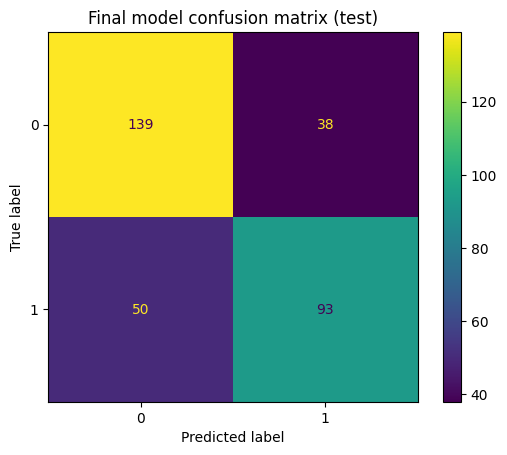


Classification report (test):
              precision    recall  f1-score   support

           0       0.74      0.79      0.76       177
           1       0.71      0.65      0.68       143

    accuracy                           0.72       320
   macro avg       0.72      0.72      0.72       320
weighted avg       0.72      0.72      0.72       320



In [13]:
# Choose the best model based on validation performance.
# If Random Forest ends up better for you, swap in best_rf here.
final_model = best_gb

# Refit on train+val
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)

final_model.fit(X_train_full, y_train_full)
y_test_pred = final_model.predict(X_test)
y_test_proba = final_model.predict_proba(X_test)[:, 1]

print("Final model performance on TEST set:")
acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred, zero_division=0)
rec = recall_score(y_test, y_test_pred, zero_division=0)
f1 = f1_score(y_test, y_test_pred, zero_division=0)
auc = roc_auc_score(y_test, y_test_proba)

print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1:        {f1:.3f}")
print(f"ROC AUC:   {auc:.3f}")

disp = ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
disp.ax_.set_title("Final model confusion matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred, zero_division=0))


## 9. Data source and related work

The data used in this notebook comes from the public Steam datasets curated by Julian McAuley and collaborators, which
have been widely used to study recommender systems and user behavior on digital platforms. In particular, different
subsets and extensions of these data have appeared in the following papers:

- Wang-Cheng Kang and Julian McAuley. **"Self-attentive sequential recommendation."** *ICDM*, 2018.  
- Mengting Wan and Julian McAuley. **"Item recommendation on monotonic behavior chains."** *RecSys*, 2018.  
- Apurva Pathak, Kshitiz Gupta, and Julian McAuley. **"Generating and personalizing bundle recommendations on Steam."**
  *SIGIR*, 2017.

Our task here is simpler than the personalized recommendation problems studied in those works: instead of modeling
individual user sequences or bundles, we aggregate reviews to the **game level** and ask whether a given title can be
classified as “successful” using a compact set of engineered features. Nevertheless, the same underlying data enable
both kinds of analyses, and the modeling choices in this notebook are consistent with the broader literature on
recommendation and user‑generated feedback.


## 10. Error analysis

The cell below attaches test-set predictions back to the full game records so individual mistakes can be inspected:

- **False positives:** games predicted successful that are labeled unsuccessful
- **False negatives:** games labeled successful that the model misses

Many misses are games with only a handful of reviews, where a single review can flip the label. That label noise caps how well any launch-time model can do. Raising the minimum review count, or adding developer/publisher history and learned text embeddings, are the most promising next steps.

In [15]:
# Attach predictions back to the test DataFrame for inspection
test_with_meta = data.loc[X_test.index].copy()
test_with_meta["y_true"] = y_test.values
test_with_meta["y_pred"] = y_test_pred
test_with_meta["y_proba"] = y_test_proba

false_positives = test_with_meta[(test_with_meta["y_true"] == 0) & (test_with_meta["y_pred"] == 1)]
false_negatives = test_with_meta[(test_with_meta["y_true"] == 1) & (test_with_meta["y_pred"] == 0)]

print("False positives (head):")
display(false_positives.head())

print("\nFalse negatives (head):")
display(false_negatives.head())


False positives (head):


,item_id,n_reviews,log_n_reviews,pos_share,success,release_year,n_genres,n_categories,text_features,y_true,y_pred,y_proba
972,258970,9,2.302585,0.666667,0,2014.0,3,20,Action Adventure RPG Co-op Dungeon Crawler Act...,0,1,0.633122
6,10220,7,2.079442,0.142857,0,2011.0,1,20,Action Action Dark Humor Gore Open World Third...,0,1,0.824249
341,212200,9,2.302585,0.666667,0,2012.0,7,16,Action Adventure Casual Free to Play Massively...,0,1,0.553855
2800,444000,1,0.693147,1.000000,0,2016.0,4,17,Indie Racing Simulation Sports Racing Sports I...,0,1,0.584693
1394,293680,1,0.693147,1.000000,0,2012.0,3,17,Adventure Indie RPG Visual Novel Female Protag...,0,1,0.512533



False negatives (head):


,item_id,n_reviews,log_n_reviews,pos_share,success,release_year,n_genres,n_categories,text_features,y_true,y_pred,y_proba
2466,393410,7,2.079442,0.857143,1,2015.0,5,8,Action Free to Play Indie Massively Multiplaye...,1,0,0.219599
1521,304670,2,1.098612,1.000000,1,2014.0,3,5,Casual Indie Strategy Strategy Indie Casual Sp...,1,0,0.239578
532,2270,6,1.945910,1.000000,1,1994.0,1,12,Action FPS Classic Action World War II Singlep...,1,0,0.360273
701,239720,2,1.098612,1.000000,1,2013.0,1,4,Action Action Platformer 3D Platformer Adventu...,1,0,0.164463
156,18500,3,1.386294,1.000000,1,2008.0,2,11,Indie Strategy Tower Defense Strategy Sci-fi I...,1,0,0.382228
